# 09 · Data and AI/ML jobs

How big are data and AI/ML jobs inside IT hiring, which kinds are they, and who hires them?

**Method.** "Data / AI jobs" are the postings whose final role (see `03-roles`) is `data` or `ai_ml`. Inside them, a second **title-only** split separates ML engineers, AI engineers, data scientists, data engineers, BI and reporting, data analysts and database admins. Titles do not depend on how long a source writes, but sources differ in role mix, so trends are drawn for all sources, CareerBuilder and LinkedIn. Seniority, experience, work mode and salary use the same definitions and the same January-2025 start as notebooks 04, 07 and 08. This notebook stays at the market level; it does not compare individual tools or frameworks.

In [1]:
import pandas as pd

from vnjobs.analysis import core as a
from vnjobs.analysis import data_ai as d

a.apply_style()
con = a.connect()
df = a.load_features(con)

## 1. How big

Share of IT postings whose role is data, AI/ML, or either.

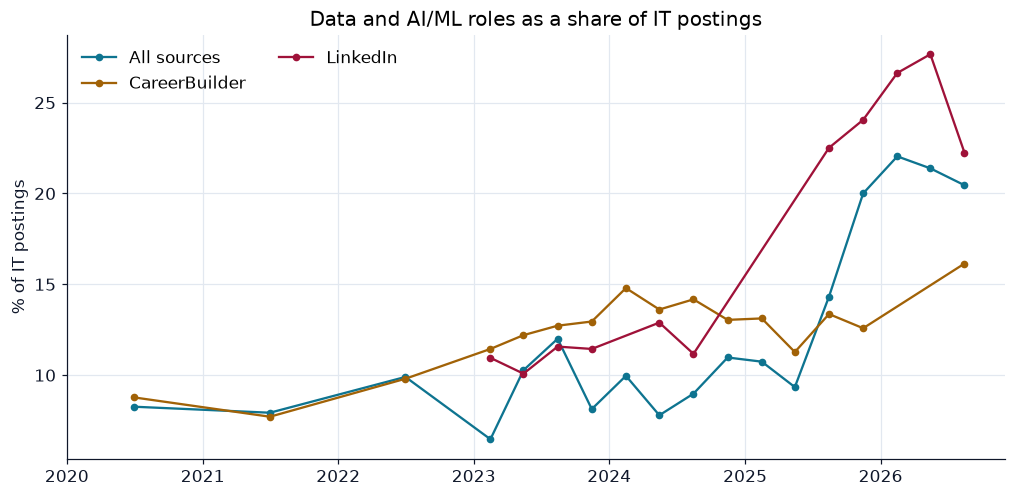

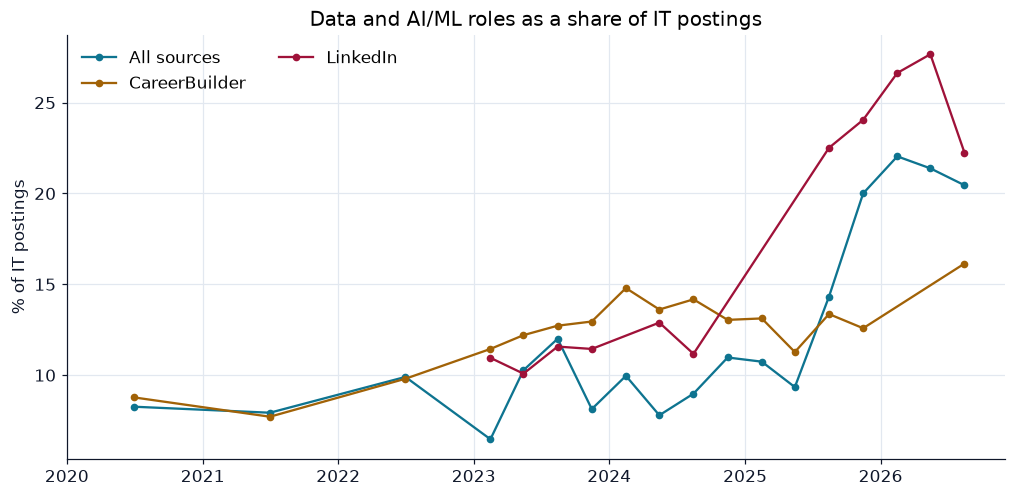

In [2]:
combined = d.share_series(df, d.DATA_AI_ROLES)
fig = a.trend_lines(combined, "Data and AI/ML roles as a share of IT postings", "% of IT postings")
a.save_chart(fig, "09-data-ai-share")
rows = [f.assign(scope=n) for n, f in combined.items()]
a.save_table(pd.concat(rows).drop(columns="period_date"), "09-data-ai-share")
fig

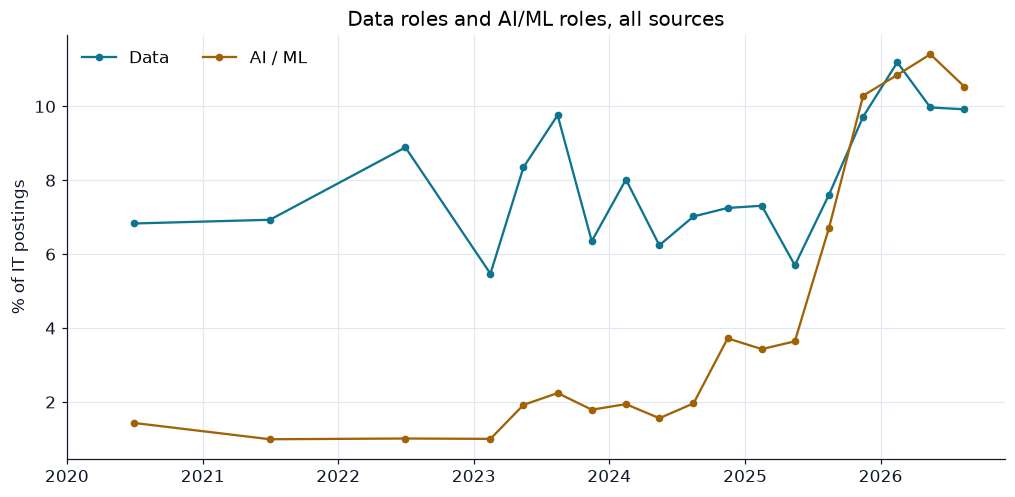

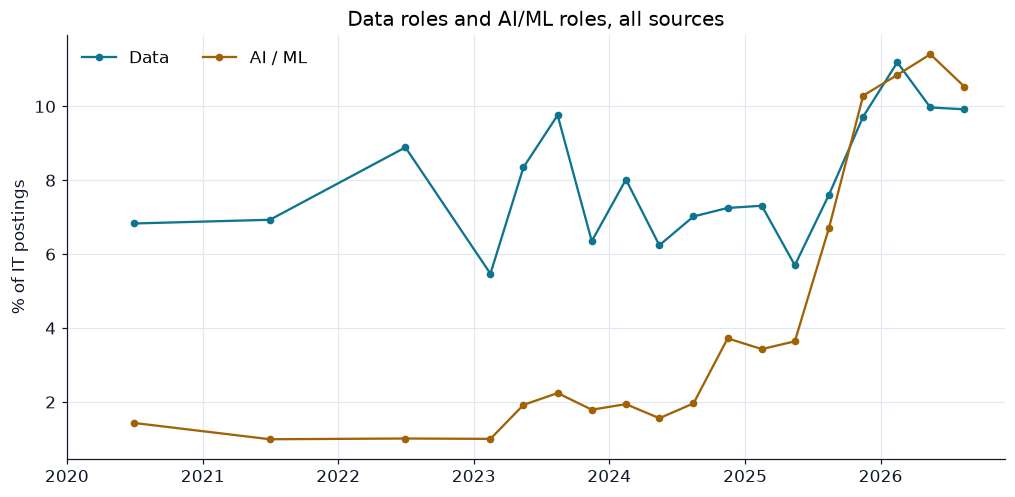

In [3]:
parts = {
    "Data": d.share_series(df, ["data"])["All sources"],
    "AI / ML": d.share_series(df, ["ai_ml"])["All sources"],
}
fig = a.trend_lines(parts, "Data roles and AI/ML roles, all sources", "% of IT postings")
a.save_chart(fig, "09-data-vs-ai-share")
fig

## 2. What kinds of data and AI jobs

A title-only split of the data and AI/ML postings into families. "Other data / AI" holds titles that name data or AI without saying what the job is.

In [4]:
ai = d.data_ai(df)
counts = ai.subrole.value_counts().reindex(d.SUBROLE_ORDER)
counts = counts.rename_axis("family").reset_index(name="postings")
counts["share"] = (100 * counts.postings / counts.postings.sum()).round(1)
a.save_table(counts, "09-data-ai-families")
counts

,family,postings,share
0,ML engineer,1331,6.7
1,AI engineer,4580,22.9
2,Data scientist,1136,5.7
3,Data engineer,3479,17.4
4,BI / reporting,939,4.7
5,Data analyst,4531,22.7
6,Database admin,1033,5.2
7,Other data / AI,2929,14.7


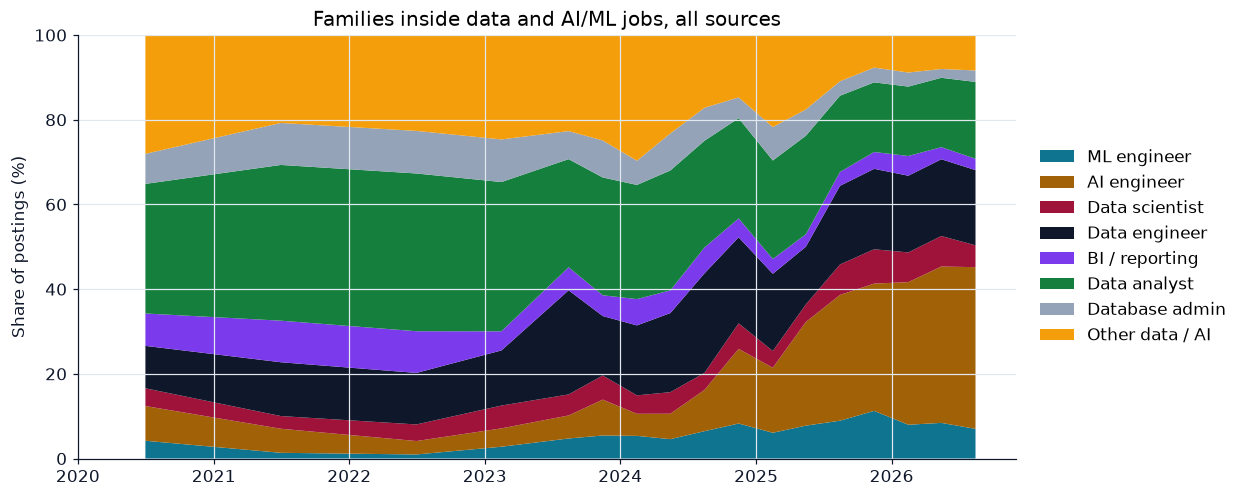

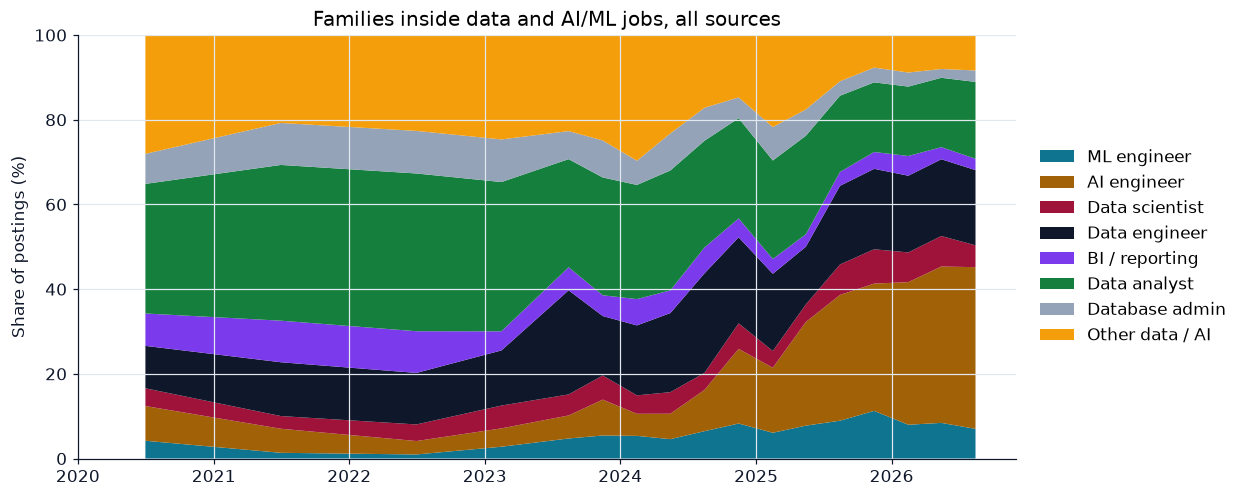

In [5]:
fig = a.stacked_share(
    ai, "subrole", d.SUBROLE_ORDER, "Families inside data and AI/ML jobs, all sources"
)
a.save_chart(fig, "09-data-ai-families")
fig

In [6]:
recent = ai[ai.month >= d.FROM_MONTH]
mix = pd.crosstab(recent.subrole, recent.group).reindex(d.SUBROLE_ORDER)
mix

group,AI / ML,Data
subrole,,
ML engineer,999,27
AI engineer,3952,114
Data scientist,770,23
Data engineer,1,2277
BI / reporting,0,442
Data analyst,17,2237
Database admin,0,420
Other data / AI,323,910


## 3. How they differ from other IT jobs

For January 2025 onward: entry-level share of known-level postings, required experience, remote and hybrid shares of postings that state a mode, the Hồ Chí Minh share and the advertised median salary. Groups with fewer than 100 salaries show no salary.

In [7]:
compare = d.comparison(df)
a.save_table(compare, "09-data-ai-comparison")
compare

,group,postings,entry_pct,median_years,pct_5_years_plus,remote_pct,hybrid_pct,hcm_pct,median_salary_m,salaries
0,Data,6450,30.6,3.0,24.8,17.1,33.4,46.0,20.0,313
1,AI / ML,6062,33.7,3.0,35.7,31.1,33.2,40.5,35.0,129
2,Other IT roles,58443,33.5,3.0,29.0,15.2,33.0,44.9,18.0,5189


## 4. What they ask for, by category

Share of tech-naming postings that name at least one tool from each category (2025 on). This is demand by *kind* of tool, not a ranking of tools.

In [8]:
demand = d.category_demand(df)
a.save_table(demand, "09-data-ai-demand")
demand

,group,language,cloud,database,data,ai,llm
0,Data,88.0,39.0,44.5,80.9,24.7,11.7
1,AI / ML,83.5,35.6,16.2,27.2,77.9,68.9
2,Other IT roles,71.4,33.7,33.4,4.7,10.0,11.5


## 5. Who hires them

Employers with the most data and AI/ML postings from January 2025, corporate groups combined.

role,company,data,ai_ml,total
0,FPT,228,186,414
1,MB Bank,98,195,293
2,Shopee,190,61,251
3,Vingroup,53,153,206
4,Viettel,103,102,205
5,Bosch,60,137,197
6,Techcombank,116,79,195
7,Mindrift,9,165,174
8,CMC,91,58,149
9,Đúng Người Đúng Việc Community,62,41,103


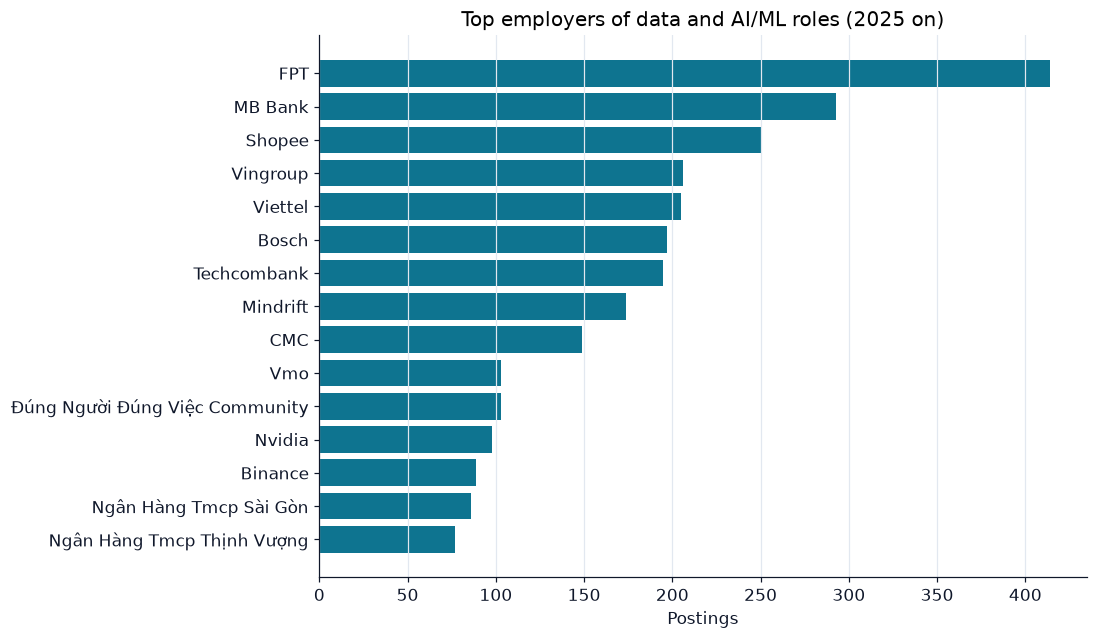

In [9]:
employers = d.top_employers(df)
a.save_table(employers, "09-data-ai-employers")
fig = a.barh(
    employers,
    "company",
    "total",
    "Top employers of data and AI/ML roles (2025 on)",
    "Postings",
)
a.save_chart(fig, "09-data-ai-employers")
employers

## Findings

1. **Data and AI/ML jobs doubled their share of IT postings, mostly in the last two years.** All sources: 7.9 % of IT postings in 2021, 6.5 % in 2023-Q1, 10.7 % in 2025-Q1, 20.5 % in 2026-Q3. CareerBuilder: 7.7 % → 11.4 % → 13.1 % → 16.1 %. LinkedIn: 11.0 % in 2023-Q1 → 22.2 % in 2026-Q3. Data roles grew slowly (about 7 % to 10 %); the jump is AI/ML (see `03-roles` and `06-ai-and-llm`).
2. **The kinds of job.** Across the whole period the data and AI/ML postings split into AI engineer (22.9 %), data analyst (22.7 %), data engineer (17.4 %), ML engineer (6.7 %), data scientist (5.7 %), database admin (5.2 %), BI and reporting (4.7 %), and 14.7 % whose title says data or AI without saying what the job is. The AI-engineer family is almost all recent.
3. **They look like other IT jobs on entry level and experience, with two differences** (January 2025 on). Entry-level share of known-level postings: data 30.6 %, AI/ML 33.7 %, other IT 33.5 %. Median required experience is 3 years in all three groups, but AI/ML asks for five years or more more often (35.7 % against 24.8 % for data and 29.0 % for other IT). AI/ML is also the most remote-friendly: 31.1 % of postings that state a mode say remote, against 17.1 % for data and 15.2 % for other IT; hybrid is about 33 % in all three.
4. **Location is no different.** Hồ Chí Minh holds 46 % of data postings, 40.5 % of AI/ML postings and 45 % of other IT postings (re-run 2026-11-07 after the city fix).
5. **Pay.** The advertised median is 20 million VND a month for data roles (313 salaries) and 18 million for other IT (5,189 salaries). AI/ML shows 35 million, but on only 129 salaries, so it is indicative at most: ads that publish a salary are a small, selective group.
6. **What they ask for, by kind of tool** (share of tech-naming postings naming at least one tool of the kind, 2025 on). Data roles: a programming language or SQL 88 %, data tooling 81 %, databases 44 %, cloud 39 %, LLM-era tools 12 %. AI/ML roles: AI/ML tools 78 %, LLM-era tools 69 %, languages 84 %, cloud 36 %, data tooling 27 %. LLM-era tools show up in 11.5 % of the other IT roles too, so they are not confined to AI jobs.
7. **Who hires them** (January 2025 on, groups combined, postings with data or AI/ML roles): FPT 414 (228 data, 186 AI/ML), MB Bank 293 (98 data, 195 AI/ML), Shopee 251 (190 data), Vingroup 206 (153 AI/ML), Viettel 205, Bosch 197 (137 AI/ML), Techcombank 195 (116 data), Mindrift 174 (165 AI/ML), CMC 149. Banks stand out (MB Bank, Techcombank), and Nvidia (98, almost all AI/ML) and Binance (89) appear in the top 15.

**What this notebook cannot say:** how many of the AI/ML postings are research or engineering roles rather than roles that only mention AI, or what AI/ML jobs pay (too few salaries).
